# Учебная Direct Sparse Odometry (DSO)

Пайплайн: grayscale/маска → выбор градиентных пикселей → инициализация глубины → фотометрическое выравнивание coarse-to-fine → оценка экспозиции → обновление ключевых кадров и глубины.

Это **упрощённая учебная прямая VO, не оригинальная DSO**. Движение оценивается напрямую по яркостям без дескрипторов. Двухкадровая геометрия и epipolar patch matching используются только для глубины. Нет оконной photometric bundle adjustment, маргинализации по Шуру и полноценной модели виньетирования/response function. Loop closing отсутствует.

In [14]:
from pathlib import Path
import csv
import json
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == 'scripts' else Path.cwd()
IMAGE_DIR = ROOT / 'images'
TIMES_PATH = ROOT / 'calib' / 'times.txt'
CALIB_PATH = ROOT / 'calib' / 'camera_orb.yaml'
RESULTS_DIR = ROOT / 'results' / 'VO' / 'DSO'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MONO_SCALE_CONSTANT = 1.0
INIT_FRAME_INDEX = 10
WORK_WIDTH = 640

plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['font.size'] = 18
print('Project root:', ROOT)

Project root: /home/sadovetsrv/dev_KAMAZ/big_dataset


## 0. Предобработка

Используем **точно ту же маску**, что в ORB: сначала линии перил и прямоугольники задаются на исходном кадре 1280×720, затем маска уменьшается до рабочего размера методом ближайшего соседа. Нулевые пиксели исключены и из выбора градиентных точек, и из фотометрической оптимизации.

Для скорости изображение уменьшается до 640×360. Матрица камеры масштабируется вместе с ним, поэтому пиксельные проекции остаются согласованными с калибровкой. Это по-прежнему временная оценка `fx/fy`, а не калибровка по шахматной доске.

Working size: (640, 360) K =
 [[262.5   0.  320. ]
 [  0.  157.5 180. ]
 [  0.    0.    1. ]]
Исключено общей маской: 27.45% исходного кадра


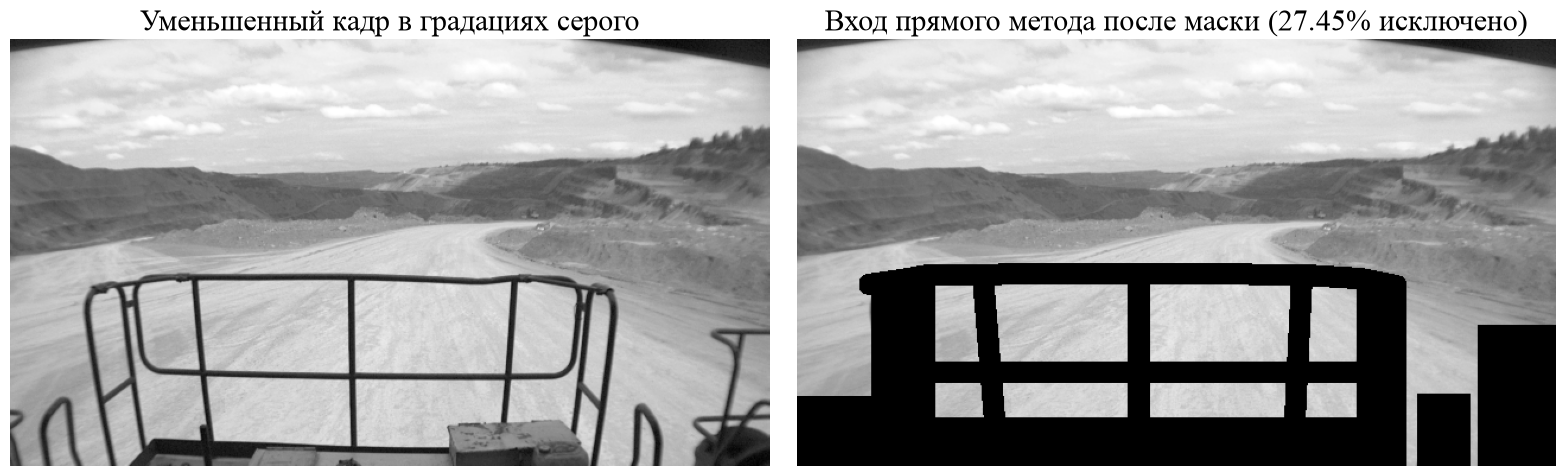

In [15]:
image_paths = sorted(IMAGE_DIR.glob('*.png'))
timestamps = np.loadtxt(TIMES_PATH)

# FileStorage открывает YAML; getNode(...).real() читает скалярные параметры камеры.
storage = cv2.FileStorage(str(CALIB_PATH), cv2.FILE_STORAGE_READ)
fx, fy = storage.getNode('Camera.fx').real(), storage.getNode('Camera.fy').real()
cx, cy = storage.getNode('Camera.cx').real(), storage.getNode('Camera.cy').real()

distortion = np.array([storage.getNode(name).real() for name in
                       ['Camera.k1', 'Camera.k2', 'Camera.p1', 'Camera.p2', 'Camera.k3']])
storage.release()

K_full = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=np.float64)

# imread загружает исходный кадр в grayscale для определения размеров.
sample_full = cv2.imread(str(image_paths[0]), cv2.IMREAD_GRAYSCALE)
full_height, full_width = sample_full.shape
work_height = round(full_height * WORK_WIDTH / full_width)
scale_xy = WORK_WIDTH / full_width
K = K_full.copy()
K[0, 0] *= scale_xy
K[1, 1] *= scale_xy
K[0, 2] *= scale_xy
K[1, 2] *= scale_xy

# initUndistortRectifyMap заранее вычисляет карту устранения дисторсии для полного кадра.
map_x, map_y = cv2.initUndistortRectifyMap(K_full, distortion, None, K_full,
                                          (full_width, full_height), cv2.CV_32FC1)

# Белый (255) — разрешённые пиксели, чёрный (0) — статические элементы машины.
raw_mask = np.full((full_height, full_width), 255, np.uint8)
RAIL_POLYLINES = [
    [(0.110, 0.575), (0.175, 0.560), (0.460, 0.552),
     (0.670, 0.566), (0.790, 0.575)],
    
    [(0.245, 0.560), (0.260, 0.900)],
    [(0.450, 0.560), (0.450, 0.900)],
    [(0.668, 0.570), (0.650, 0.900)],
    
    [(0.175, 0.770), (0.460, 0.790), (0.735, 0.785)],
]
STATIC_RECTANGLES = [
    (0.000, 0.840, 0.100, 1.000),  # Перила в левой нижней части кадра.
    (0.100, 0.580, 0.180, 1.000),  # Перила слева "вверх".
    (0.120, 0.890, 0.800, 1.000),  # Нижняя площадка.
    (0.740, 0.580, 0.800, 1.000),  # Перила справа "вверх".
    (0.820, 0.835, 0.885, 1.000),  # Перила справа "между".
    (0.900, 0.675, 1.000, 1.000),  # Перила в правой нижней части кадра.
]
RAIL_THICKNESS_PX = max(5, round(min(full_height, full_width) * 0.04))
MASK_MARGIN_PX = 3

def normalized_to_pixel(point):
    x, y = point
    return round(x * (full_width - 1)), round(y * (full_height - 1))

for polyline in RAIL_POLYLINES:
    points = np.array([normalized_to_pixel(point) for point in polyline], dtype=np.int32)
    # polylines закрашивает ломаную нулём; LINE_AA сглаживает границу линии.
    cv2.polylines(raw_mask, [points], False, 0, RAIL_THICKNESS_PX, cv2.LINE_AA)
for x1, y1, x2, y2 in STATIC_RECTANGLES:
    # thickness=-1 в rectangle закрашивает всю прямоугольную область.
    cv2.rectangle(raw_mask, normalized_to_pixel((x1, y1)),
                  normalized_to_pixel((x2, y2)), 0, thickness=-1)

excluded_mask = 255 - raw_mask
if MASK_MARGIN_PX > 0:
    kernel_size = 2 * MASK_MARGIN_PX + 1
    # dilate расширяет исключённые области на заданный запас во все стороны.
    excluded_mask = cv2.dilate(excluded_mask, np.ones((kernel_size, kernel_size), np.uint8))
raw_mask = 255 - excluded_mask
excluded_percent = 100.0 * np.count_nonzero(raw_mask == 0) / raw_mask.size

def load_gray(index):
    # imread читает кадр; remap устраняет дисторсию по заранее построенным картам.
    gray = cv2.imread(str(image_paths[index]), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise RuntimeError(f'Cannot read {image_paths[index]}')
    gray = cv2.remap(gray, map_x, map_y, cv2.INTER_LINEAR)
    # INTER_AREA уменьшает изображение с усреднением; float32 нужен для невязок яркости.
    return cv2.resize(gray, (WORK_WIDTH, work_height), interpolation=cv2.INTER_AREA).astype(np.float32)

# INTER_NEAREST сохраняет бинарную маску без промежуточных полуразрешённых значений.
feature_mask = cv2.resize(raw_mask, (WORK_WIDTH, work_height), interpolation=cv2.INTER_NEAREST)
print('Working size:', (WORK_WIDTH, work_height), 'K =\n', K)
print(f'Исключено общей маской: {excluded_percent:.2f}% исходного кадра')
figure, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(load_gray(0), cmap='gray')
axes[0].axis('off')
axes[0].set_title('Уменьшенный кадр в градациях серого')
masked_preview = load_gray(0).copy()
masked_preview[feature_mask == 0] = 0
axes[1].imshow(masked_preview, cmap='gray')
axes[1].axis('off')
axes[1].set_title(f'Вход прямого метода после маски ({excluded_percent:.2f}% исключено)')
figure.tight_layout()
figure.savefig(RESULTS_DIR / 'dso_preprocessing.png', dpi=200, bbox_inches='tight')

## 1. Point Selection: градиентные пиксели

DSO не ищет углы и не строит дескрипторы. Для фотометрической невязки полезны пиксели с достаточным градиентом: на равномерном небе или дороге изменение яркости почти не ограничивает движение. Порог подбирается по процентилю градиента.

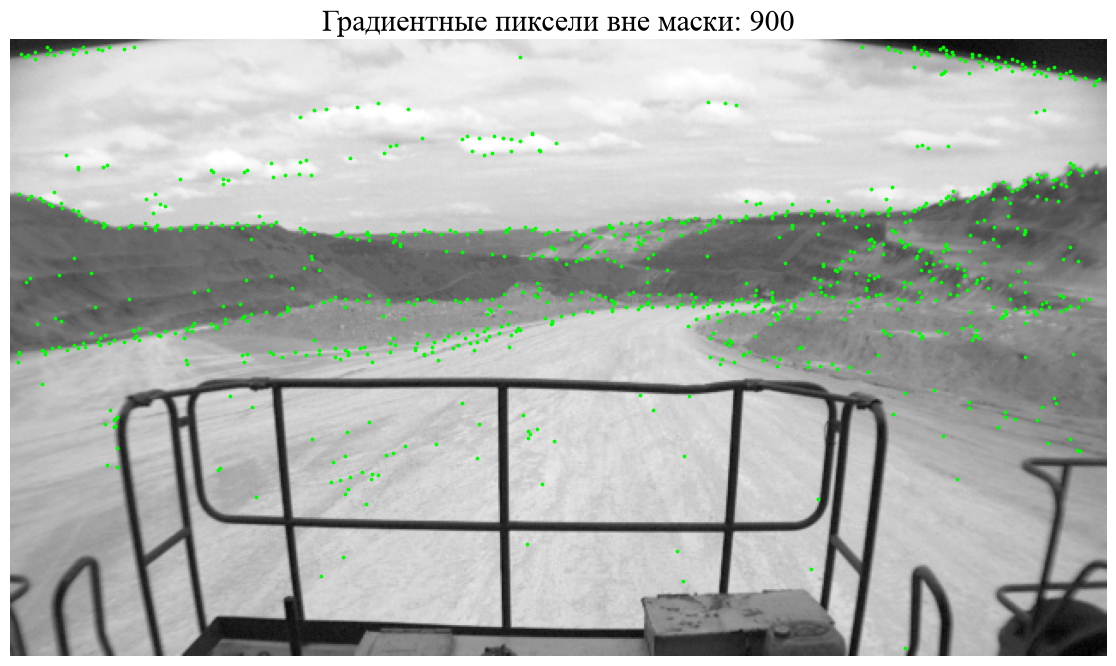

In [16]:
def gradient_image(gray):
    # Sobel вычисляет производные яркости по x/y; CV_32F сохраняет знак и дробные значения.
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3) / 8.0
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3) / 8.0
    return gx, gy, np.hypot(gx, gy)

def select_gradient_pixels(gray, count=900, excluded_points=None):
    _, _, magnitude = gradient_image(gray)
    allowed = (feature_mask > 0).copy()
    # Четырёхпиксельная рамка нужна для устойчивой билинейной интерполяции и патчей.
    allowed[:4, :] = False
    allowed[-4:, :] = False
    allowed[:, :4] = False
    allowed[:, -4:] = False
    if excluded_points is not None and len(excluded_points):
        for x, y in np.round(excluded_points).astype(int):
            if 0 <= x < WORK_WIDTH and 0 <= y < work_height:
                allowed[max(0, y - 3):y + 4, max(0, x - 3):x + 4] = False
    values = magnitude[allowed]
    threshold = np.percentile(values, 80) if len(values) else 10
    candidates = np.argwhere(allowed & (magnitude >= max(8.0, threshold)))
    if not len(candidates):
        return np.empty((0, 2), np.float32)
    # Равномерно прореживаем отсортированные координаты, ограничивая вычислительную нагрузку.
    chosen = np.linspace(0, len(candidates) - 1, min(count, len(candidates))).astype(int)
    yx = candidates[chosen]
    return yx[:, ::-1].astype(np.float32)

demo_pixels = select_gradient_pixels(load_gray(0))
figure, axis = plt.subplots(figsize=(13, 7))
axis.imshow(load_gray(0), cmap='gray')
axis.scatter(demo_pixels[:, 0], demo_pixels[:, 1], s=3, color='lime')
axis.set_title(f'Градиентные пиксели вне маски: {len(demo_pixels)}')
axis.axis('off')
figure.tight_layout()
figure.savefig(RESULTS_DIR / 'dso_gradient_points.png', dpi=200, bbox_inches='tight')

## 2. Depth Initialization

Одно изображение глубину не даёт. Для начальной карты на кадрах 0 и 10 используем стандартную двухкадровую геометрию: ORB здесь нужен **только для начальной глубины**, а не для последующего трекинга. Оригинальная DSO вместо этого оптимизирует несколько кадров фотометрически. Начальный масштаб снова произвольный.

In [17]:
def make_pose(R=np.eye(3), t=np.zeros(3)):
    pose = np.eye(4)
    pose[:3, :3] = R
    pose[:3, 3] = t
    return pose

def triangulate_points(pose_ref, pose_cur, pixels_ref, pixels_cur):
    P_ref = K @ pose_ref[:3, :]
    P_cur = K @ pose_cur[:3, :]
    # triangulatePoints пересекает лучи соответствий и возвращает однородные точки 4×N.
    homogeneous = cv2.triangulatePoints(P_ref, P_cur, np.asarray(pixels_ref, dtype=np.float64).T,
                                       np.asarray(pixels_cur, dtype=np.float64).T)
    xyz_ref = (homogeneous[:3] / homogeneous[3]).T
    xyz_cur = (pose_cur[:3, :3] @ (pose_ref[:3, :3].T @ (xyz_ref - pose_ref[:3, 3]).T + pose_cur[:3, 3:4])).T
    valid = np.isfinite(xyz_ref).all(axis=1) & (xyz_ref[:, 2] > 0) & (xyz_cur[:, 2] > 0)
    world = (pose_ref[:3, :3].T @ (xyz_ref - pose_ref[:3, 3]).T).T
    return world, xyz_ref, xyz_cur, valid

gray_init0 = load_gray(0).astype(np.uint8)
gray_init1 = load_gray(INIT_FRAME_INDEX).astype(np.uint8)
# ORB_create и detectAndCompute используются только для учебной инициализации глубины.
orb_bootstrap = cv2.ORB_create(nfeatures=2500, fastThreshold=15)
kp0, desc0 = orb_bootstrap.detectAndCompute(gray_init0, feature_mask)
kp1, desc1 = orb_bootstrap.detectAndCompute(gray_init1, feature_mask)
# BFMatcher(NORM_HAMMING) сравнивает бинарные дескрипторы; knnMatch даёт двух соседей.
matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
raw = matcher.knnMatch(desc0, desc1, k=2)
bootstrap_matches = [pair[0] for pair in raw if len(pair) == 2 and pair[0].distance < 0.75 * pair[1].distance]
bootstrap_p0 = np.float32([kp0[m.queryIdx].pt for m in bootstrap_matches])
bootstrap_p1 = np.float32([kp1[m.trainIdx].pt for m in bootstrap_matches])
# findEssentialMat + RANSAC отбрасывает ошибочные соответствия при инициализации.
E, bootstrap_mask = cv2.findEssentialMat(bootstrap_p0, bootstrap_p1, K, cv2.RANSAC, 0.999, 1.0)
# recoverPose выбирает поворот и направление перевода с положительной глубиной.
_, R0, t0, depth_mask = cv2.recoverPose(E, bootstrap_p0, bootstrap_p1, K, mask=bootstrap_mask.copy())
pose0 = make_pose()
pose1 = make_pose(R0, MONO_SCALE_CONSTANT * t0.ravel())
world0, xyz_ref0, xyz_cur0, valid0 = triangulate_points(pose0, pose1, bootstrap_p0, bootstrap_p1)
valid0 &= (depth_mask.ravel() > 0)
initial_world = world0[valid0]
initial_pixels = bootstrap_p0[valid0]
print(f'Bootstrap matches: {len(bootstrap_matches)}; 3D points: {len(initial_world)}')
print(f'Initial scale: {MONO_SCALE_CONSTANT} arbitrary units, not metres')
if len(initial_world) < 30:
    raise RuntimeError('Insufficient bootstrap depth')
print('ВЫВОД: получены начальная поза и разреженная 3D-карта в условных единицах.')

Bootstrap matches: 345; 3D points: 171
Initial scale: 1.0 arbitrary units, not metres
ВЫВОД: получены начальная поза и разреженная 3D-карта в условных единицах.


## 3. Photometric Error

Для точки `p` с известной глубиной проецируем её в текущий кадр и сравниваем яркости: `r = I_current(π(Tp)) - (a I_reference(p) + b)`. Параметры `a,b` грубо компенсируют изменение экспозиции. В отличие от ORB нет Hamming-расстояния и дескрипторного matching.

In [18]:
def sample_bilinear(image, xy):
    # remap с отдельными картами x/y выполняет билинейную выборку яркости в дробных координатах.
    return cv2.remap(image, xy[:, 0:1].astype(np.float32), xy[:, 1:2].astype(np.float32),
                     cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0).ravel()

def skew(vector):
    # Кососимметричная матрица задаёт векторное произведение для Якобиана вращения.
    x, y, z = vector
    return np.array([[0, -z, y], [z, 0, -x], [-y, x, 0]], dtype=np.float64)

def exp_se3(xi):
    pose = np.eye(4)
    # Rodrigues переводит вектор малого вращения в матрицу; xi[:3] — приращение перевода.
    pose[:3, :3] = cv2.Rodrigues(xi[3:])[0]
    pose[:3, 3] = xi[:3]
    return pose

def rotation_angle(R):
    return np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1)))

def project_world(pose, world_points, camera_matrix):
    camera = (pose[:3, :3] @ world_points.T + pose[:3, 3:4]).T
    projected = (camera_matrix @ camera.T).T
    pixels = projected[:, :2] / np.maximum(projected[:, 2:3], 1e-9)
    return camera, pixels

def inside_feature_mask(pixels):
    # Клиппинг делает индексацию безопасной; границы отдельно проверяются геометрическими условиями.
    xy = np.round(pixels).astype(int)
    xy[:, 0] = np.clip(xy[:, 0], 0, WORK_WIDTH - 1)
    xy[:, 1] = np.clip(xy[:, 1], 0, work_height - 1)
    return feature_mask[xy[:, 1], xy[:, 0]] > 0

## 4. Coarse-to-Fine Direct Image Alignment

Гаусс–Ньютон минимизирует фотометрическую невязку по 6 параметрам `SE(3)`. На грубом уровне захватываем большое движение, затем уточняем на детальном. Huber weights уменьшают влияние окклюзий и движущихся объектов. Это главный этап прямого трекинга.

In [19]:
def direct_align(reference, current_gray, initial_pose):
    pose = initial_pose.copy()
    final = {'valid_points': 0, 'median_residual': np.nan, 'affine_a': 1.0, 'affine_b': 0.0}
    for level in [2, 1, 0]:
        factor = 1.0 / (2 ** level)
        level_width, level_height = round(WORK_WIDTH * factor), round(work_height * factor)
        # INTER_AREA строит пирамиду изображений от грубого масштаба к исходному рабочему.
        current = cv2.resize(current_gray, (level_width, level_height), interpolation=cv2.INTER_AREA)
        reference_level = cv2.resize(reference['gray'], (level_width, level_height), interpolation=cv2.INTER_AREA)
        level_mask = cv2.resize(feature_mask, (level_width, level_height), interpolation=cv2.INTER_NEAREST)
        ref_pixels = reference['pixels'] * factor
        ref_values = sample_bilinear(reference_level, ref_pixels)
        K_level = K.copy()
        K_level[0, 0] *= factor
        K_level[1, 1] *= factor
        K_level[0, 2] *= factor
        K_level[1, 2] *= factor
        # Sobel даёт градиенты текущего изображения для фотометрического Якобиана.
        gx = cv2.Sobel(current, cv2.CV_32F, 1, 0, ksize=3) / 8.0
        gy = cv2.Sobel(current, cv2.CV_32F, 0, 1, ksize=3) / 8.0
        for iteration in range(12):
            camera, pixels = project_world(pose, reference['world'], K_level)
            valid = ((camera[:, 2] > 0.05) & (pixels[:, 0] > 3) & (pixels[:, 0] < level_width - 4)
                     & (pixels[:, 1] > 3) & (pixels[:, 1] < level_height - 4))
            # Даже спроецированная точка не должна попадать на перила или другие нулевые зоны маски.
            mask_xy = np.round(pixels).astype(int)
            mask_xy[:, 0] = np.clip(mask_xy[:, 0], 0, level_width - 1)
            mask_xy[:, 1] = np.clip(mask_xy[:, 1], 0, level_height - 1)
            valid &= level_mask[mask_xy[:, 1], mask_xy[:, 0]] > 0
            indices = np.flatnonzero(valid)
            if len(indices) < 20:
                return pose, final
            uv = pixels[indices]
            current_values = sample_bilinear(current, uv)
            ref = ref_values[indices]
            # Грубая аффинная модель компенсирует изменение контраста a и яркости b.
            a = np.clip(np.std(current_values) / max(np.std(ref), 1e-3), 0.7, 1.3)
            b = np.clip(np.median(current_values - a * ref), -30, 30)
            residual = current_values - (a * ref + b)
            huber_delta = 15.0
            # Веса Хьюбера уменьшают влияние больших невязок, окклюзий и движущихся объектов.
            weights = np.minimum(1.0, huber_delta / np.maximum(np.abs(residual), 1e-6))
            X, Y, Z = camera[indices].T
            projection_jacobian = np.zeros((len(indices), 2, 3))
            projection_jacobian[:, 0, 0] = K_level[0, 0] / Z
            projection_jacobian[:, 0, 2] = -K_level[0, 0] * X / Z ** 2
            projection_jacobian[:, 1, 1] = K_level[1, 1] / Z
            projection_jacobian[:, 1, 2] = -K_level[1, 1] * Y / Z ** 2
            pose_jacobian = np.zeros((len(indices), 3, 6))
            pose_jacobian[:, :, :3] = np.eye(3)
            for point_index, point in enumerate(camera[indices]):
                pose_jacobian[point_index, :, 3:] = -skew(point)
            image_gradient = np.column_stack((sample_bilinear(gx, uv), sample_bilinear(gy, uv)))
            J = np.einsum('ni,nij,njk->nk', image_gradient, projection_jacobian, pose_jacobian)
            JW = J * weights[:, None]
            H = J.T @ JW + np.eye(6) * 1e-4
            gradient = JW.T @ residual
            try:
                # Решаем нормальные уравнения Гаусса—Ньютона для шести параметров SE(3).
                delta = np.linalg.solve(H, -gradient)
            except np.linalg.LinAlgError:
                break
            # Ограничение шага предотвращает одно чрезмерное обновление позы.
            delta = np.clip(delta, [-0.2, -0.2, -0.2, -0.05, -0.05, -0.05],
                            [0.2, 0.2, 0.2, 0.05, 0.05, 0.05])
            pose = exp_se3(delta) @ pose
            final = {'valid_points': len(indices), 'median_residual': float(np.median(np.abs(residual))),
                     'affine_a': float(a), 'affine_b': float(b)}
            if np.linalg.norm(delta[3:]) < 1e-5 and np.linalg.norm(delta[:3]) < 1e-4:
                break
    return pose, final

reference = {'index': 0, 'gray': load_gray(0), 'pixels': initial_pixels,
             'world': initial_world, 'pose': pose0}
demo_pose, demo_info = direct_align(reference, load_gray(1), pose0.copy())
print('Direct alignment demo frame 0->1:', demo_info)
print('Rotation change, deg:', rotation_angle(demo_pose[:3, :3]))
print('ВЫВОД: движение оценено по невязке яркостей; ORB-дескрипторы на этом этапе не используются.')

Direct alignment demo frame 0->1: {'valid_points': 171, 'median_residual': 2.36083984375, 'affine_a': 0.9505754113197327, 'affine_b': 6.167716979980469}
Rotation change, deg: 0.30460381281837295
ВЫВОД: движение оценено по невязке яркостей; ORB-дескрипторы на этом этапе не используются.


## 5. Depth Estimation и ключевые кадры

При смене ключевого кадра старые 3D-точки проецируются в него. Новые градиентные пиксели получают глубину поиском патча вдоль эпиполярной линии при уже известной позе. Это не feature tracking по дескрипторам: геометрия ограничивает поиск, а критерий — яркостное сходство патчей.

In [20]:
def epipolar_depth_update(reference, current_gray, current_pose, max_new=350):
    camera_points, pixels = project_world(current_pose, reference['world'], K)
    valid = ((camera_points[:, 2] > 0.05) & (pixels[:, 0] > 4) & (pixels[:, 0] < WORK_WIDTH - 5)
             & (pixels[:, 1] > 4) & (pixels[:, 1] < work_height - 5))
    # Сохраняем только старые 3D-точки, проецирующиеся в разрешённую часть нового кадра.
    valid &= inside_feature_mask(pixels)
    pixels = pixels[valid]
    world_points = reference['world'][valid]
    values = sample_bilinear(current_gray, pixels)
    ref_values = sample_bilinear(reference['gray'], reference['pixels'][valid])
    photometric = np.abs(values - ref_values) < 45
    pixels, world_points = pixels[photometric], world_points[photometric]
    candidates = select_gradient_pixels(current_gray, max_new, excluded_points=pixels)
    if len(candidates) < 10:
        return pixels, world_points, 0

    relative = current_pose @ np.linalg.inv(reference['pose'])
    R_rel, t_rel = relative[:3, :3], relative[:3, 3]
    K_inv = np.linalg.inv(K)
    median_depth = np.median(camera_points[:, 2]) if len(camera_points) else 1.0
    depth_samples = median_depth * np.linspace(0.35, 2.8, 32)
    current_uint = current_gray.astype(np.uint8)
    reference_uint = reference['gray'].astype(np.uint8)
    new_world = []
    new_pixels = []
    for pixel in candidates:
        x, y = pixel
        # Патч 5×5 сравнивает локальную текстуру, а не одиночный шумный пиксель.
        patch_current = current_uint[int(y) - 2:int(y) + 3, int(x) - 2:int(x) + 3].astype(np.float32)
        if patch_current.shape != (5, 5):
            continue
        ray = K_inv @ np.array([x, y, 1.0])
        points_cur = depth_samples[:, None] * ray[None, :]
        points_ref = (R_rel @ points_cur.T + t_rel[:, None]).T
        projections = (K @ points_ref.T).T
        uv = projections[:, :2] / np.maximum(projections[:, 2:3], 1e-9)
        valid_uv = ((points_ref[:, 2] > 0) & (uv[:, 0] >= 2) & (uv[:, 0] < WORK_WIDTH - 3)
                    & (uv[:, 1] >= 2) & (uv[:, 1] < work_height - 3))
        # Эпиполярный поиск также не должен попадать на статические элементы опорного кадра.
        valid_uv &= inside_feature_mask(uv)
        if valid_uv.sum() < 5:
            continue
        scores = []
        locations = []
        for location in uv[valid_uv]:
            px, py = np.round(location).astype(int)
            patch_ref = reference_uint[py - 2:py + 3, px - 2:px + 3].astype(np.float32)
            if patch_ref.shape != (5, 5):
                continue
            scores.append(np.mean(np.abs(patch_current - patch_ref)))
            locations.append(location)
        if len(scores) < 5:
            continue
        best = int(np.argmin(scores))
        if scores[best] > 18:
            continue
        # Триангулируем лучшую яркостную гипотезу глубины и проверяем положительную Z.
        new_world_one, xyz_ref_one, xyz_cur_one, valid_one = triangulate_points(
            reference['pose'], current_pose, locations[best][None, :], pixel[None, :])
        if valid_one[0]:
            new_world.append(new_world_one[0])
            new_pixels.append(pixel)
    if new_world:
        pixels = np.vstack((pixels, np.asarray(new_pixels)))
        world_points = np.vstack((world_points, np.asarray(new_world)))
    return pixels, world_points, len(new_world)

print('Depth-update helper ready')
print('ВЫВОД: при смене ключевого кадра глубина пополняется яркостным поиском вдоль эпиполярной линии.')

Depth-update helper ready
ВЫВОД: при смене ключевого кадра глубина пополняется яркостным поиском вдоль эпиполярной линии.


## 6. Полный последовательный трекинг

Поза инициализируется предыдущей, затем уточняется прямым выравниванием. Отбраковываем кадры с малым числом точек или большой невязкой. Новый ключевой кадр создаётся каждые 5 кадров или при уменьшении видимых точек. Потерянные кадры не интерполируются.

In [21]:
reference = {'index': 0, 'gray': load_gray(0), 'pixels': initial_pixels,
             'world': initial_world, 'pose': pose0}
successful_poses = {0: pose0.copy(), INIT_FRAME_INDEX: pose1.copy()}
# Для итоговой учебной карты сохраняем облака всех ключевых кадров в мировой системе.
map_cloud = [initial_world.copy()]
diagnostics = [
    {'frame': 0, 'timestamp': timestamps[0], 'valid_points': len(initial_world),
     'median_residual': np.nan, 'affine_a': 1.0, 'affine_b': 0.0, 'new_depth_points': 0,
     'keyframe': 1, 'runtime_s': 0.0, 'status': 'initialization_origin'},
    {'frame': INIT_FRAME_INDEX, 'timestamp': timestamps[INIT_FRAME_INDEX], 'valid_points': len(initial_world),
     'median_residual': np.nan, 'affine_a': 1.0, 'affine_b': 0.0, 'new_depth_points': 0,
     'keyframe': 0, 'runtime_s': 0.0, 'status': 'initialized'},
]
last_pose = pose1.copy()
reference['pose'] = pose0.copy()

for frame_index in range(INIT_FRAME_INDEX + 1, len(image_paths)):
    started = time.perf_counter()
    current_gray = load_gray(frame_index)
    # Начальное приближение — предыдущая поза; direct_align уточняет её по яркостям.
    estimated_pose, info = direct_align(reference, current_gray, last_pose.copy())
    previous_relative = last_pose @ np.linalg.inv(reference['pose'])
    proposed_relative = estimated_pose @ np.linalg.inv(reference['pose'])
    translation_jump = np.linalg.norm(proposed_relative[:3, 3] - previous_relative[:3, 3])
    rotation_jump = rotation_angle(proposed_relative[:3, :3] @ previous_relative[:3, :3].T)
    success = (info['valid_points'] >= 25 and info['median_residual'] < 25
               and translation_jump < 2.0 and rotation_jump < 20 and np.isfinite(estimated_pose).all())
    new_depth_points = 0
    is_keyframe = False
    if success:
        successful_poses[frame_index] = estimated_pose.copy()
        last_pose = estimated_pose.copy()
        elapsed = frame_index - reference['index']
        if elapsed >= 5 or info['valid_points'] < 100:
            pixels, world_points, new_depth_points = epipolar_depth_update(reference, current_gray, estimated_pose)
            if len(pixels) >= 30:
                reference = {'index': frame_index, 'gray': current_gray, 'pixels': pixels,
                             'world': world_points, 'pose': estimated_pose.copy()}
                map_cloud.append(world_points.copy())
                is_keyframe = True
    diagnostics.append({'frame': frame_index, 'timestamp': timestamps[frame_index],
                        'valid_points': info['valid_points'], 'median_residual': info['median_residual'],
                        'affine_a': info['affine_a'], 'affine_b': info['affine_b'],
                        'new_depth_points': new_depth_points, 'keyframe': int(is_keyframe),
                        'runtime_s': time.perf_counter() - started,
                        'status': 'tracked' if success else 'lost'})
    if frame_index % 50 == 0 or not success:
        print(f'Frame {frame_index}: {diagnostics[-1]["status"]}, points={info["valid_points"]}, '
              f'residual={info["median_residual"]:.2f}, jump={translation_jump:.3f}')

lost_frames = [row['frame'] for row in diagnostics if row['status'] == 'lost']
print(f'Tracked: {len(successful_poses)}/{len(image_paths)}; lost: {len(lost_frames)}; '
      f'keyframes: {sum(row["keyframe"] for row in diagnostics)}')
print('ВЫВОД: получены позы успешно выровненных кадров; потерянные кадры не интерполируются.')

Frame 50: tracked, points=916, residual=3.29, jump=0.035
Frame 100: tracked, points=1687, residual=2.72, jump=0.008
Frame 150: tracked, points=2685, residual=2.66, jump=0.008
Frame 200: tracked, points=3681, residual=2.21, jump=0.008
Frame 250: tracked, points=4844, residual=2.11, jump=0.010
Frame 300: tracked, points=5769, residual=2.92, jump=0.010
Frame 350: tracked, points=5875, residual=2.40, jump=0.016
Frame 400: tracked, points=2273, residual=1.91, jump=0.002
Frame 450: tracked, points=3034, residual=1.86, jump=0.006
Frame 500: tracked, points=3867, residual=1.78, jump=0.004
Frame 550: tracked, points=4427, residual=1.73, jump=0.006
Tracked: 590/599; lost: 0; keyframes: 119
ВЫВОД: получены позы успешно выровненных кадров; потерянные кадры не интерполируются.


## 7. Масштаб и локальная траектория

Координаты сохраняются в произвольных единицах начальной двухкадровой карты. Высота камеры на шкафу управления БЕЛАЗа не используется как фиктивный масштаб. Для метрической оценки позже применяется один Sim(3) ко всей траектории, а не отдельные поправки по участкам.

Saved 590 TUM poses


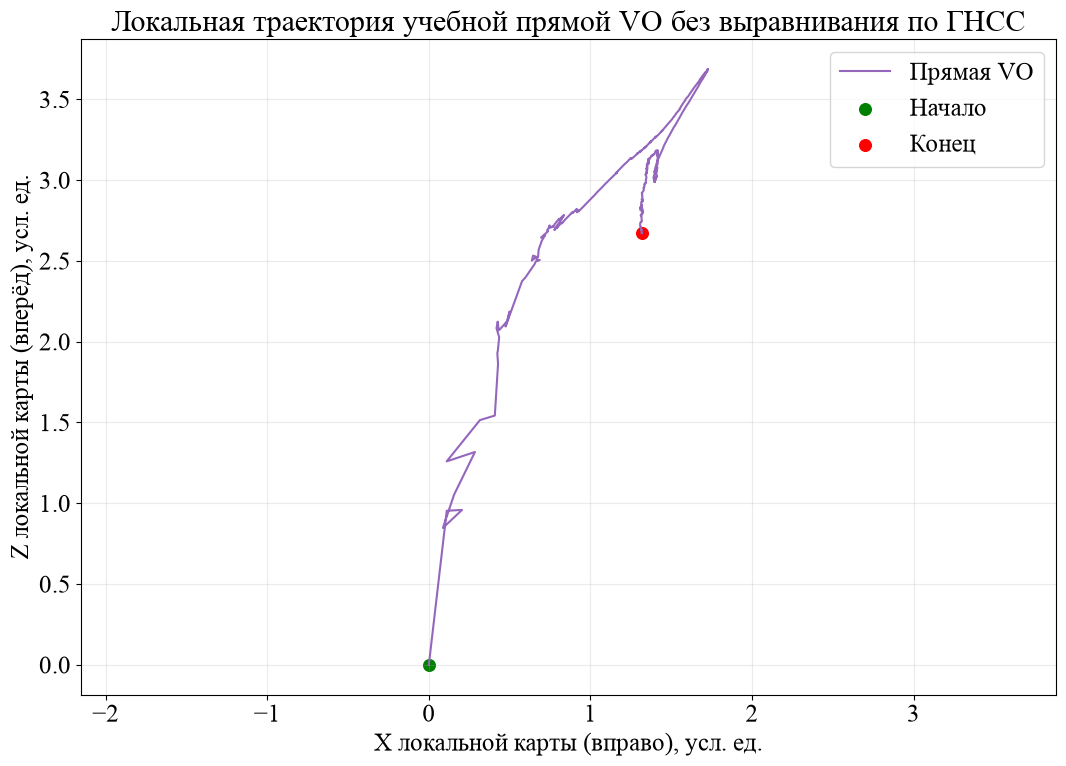

In [22]:
def rotation_to_quaternion(R):
    # Устойчивый перевод матрицы поворота в нормированный кватернион для TUM.
    trace = np.trace(R)
    if trace > 0:
        s = np.sqrt(trace + 1.0) * 2
        qw = 0.25 * s
        qx, qy, qz = (R[2, 1] - R[1, 2]) / s, (R[0, 2] - R[2, 0]) / s, (R[1, 0] - R[0, 1]) / s
    else:
        index = int(np.argmax(np.diag(R)))
        if index == 0:
            s = np.sqrt(1.0 + R[0, 0] - R[1, 1] - R[2, 2]) * 2
            qw, qx = (R[2, 1] - R[1, 2]) / s, 0.25 * s
            qy, qz = (R[0, 1] + R[1, 0]) / s, (R[0, 2] + R[2, 0]) / s
        elif index == 1:
            s = np.sqrt(1.0 + R[1, 1] - R[0, 0] - R[2, 2]) * 2
            qw, qy = (R[0, 2] - R[2, 0]) / s, 0.25 * s
            qx, qz = (R[0, 1] + R[1, 0]) / s, (R[1, 2] + R[2, 1]) / s
        else:
            s = np.sqrt(1.0 + R[2, 2] - R[0, 0] - R[1, 1]) * 2
            qw, qz = (R[1, 0] - R[0, 1]) / s, 0.25 * s
            qx, qy = (R[0, 2] + R[2, 0]) / s, (R[1, 2] + R[2, 1]) / s
    quaternion = np.array([qx, qy, qz, qw])
    return quaternion / np.linalg.norm(quaternion)

with (RESULTS_DIR / 'dso_tum.txt').open('w', encoding='utf-8') as stream:
    for index, pose in sorted(successful_poses.items()):
        # TUM хранит camera→world: центр камеры и обратную ориентацию.
        center = -pose[:3, :3].T @ pose[:3, 3]
        quaternion = rotation_to_quaternion(pose[:3, :3].T)
        values = [timestamps[index], *center, *quaternion]
        stream.write(' '.join(f'{value:.9f}' for value in values) + '\n')
with (RESULTS_DIR / 'dso_metrics.csv').open('w', newline='', encoding='utf-8') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(diagnostics[0]))
    writer.writeheader()
    writer.writerows(diagnostics)

centers = np.array([-pose[:3, :3].T @ pose[:3, 3] for _, pose in sorted(successful_poses.items())])
figure, axis = plt.subplots(figsize=(11, 8))
axis.plot(centers[:, 0], centers[:, 2], color='tab:purple', linewidth=1.5, label='Прямая VO')
axis.scatter(*centers[0, [0, 2]], color='green', s=70, label='Начало')
axis.scatter(*centers[-1, [0, 2]], color='red', s=70, label='Конец')
axis.set(xlabel='X локальной карты (вправо), усл. ед.',
         ylabel='Z локальной карты (вперёд), усл. ед.',
         title='Локальная траектория учебной прямой VO без выравнивания по ГНСС')
axis.axis('equal')
axis.grid(alpha=0.25)
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS_DIR / 'dso_trajectory_local.png', dpi=200, bbox_inches='tight')
print('Saved', len(successful_poses), 'TUM poses')

## 8. Разреженная карта

Объединяем 3D-точки всех ключевых кадров и показываем их проекцию на плоскость X/Z вместе с траекторией камеры. Это **учебная разреженная карта**: точки могут дублироваться между ключевыми кадрами, а ошибочная глубина и дрейф масштаба не устраняются полноценной оптимизацией. Цвет траектории отличает движение камеры от точек сцены. Для читаемого масштаба рисунка показаны центральные 96% точек по X и Z; редкие выбросы глубины не удаляются из расчётов, а только не попадают на визуализацию.

Карта: 422700 конечных 3D-точек; центральная область: 395269; на рисунке 5000
ВЫВОД: карта показывает геометрический результат прямого метода, но не доказывает метрическую точность.


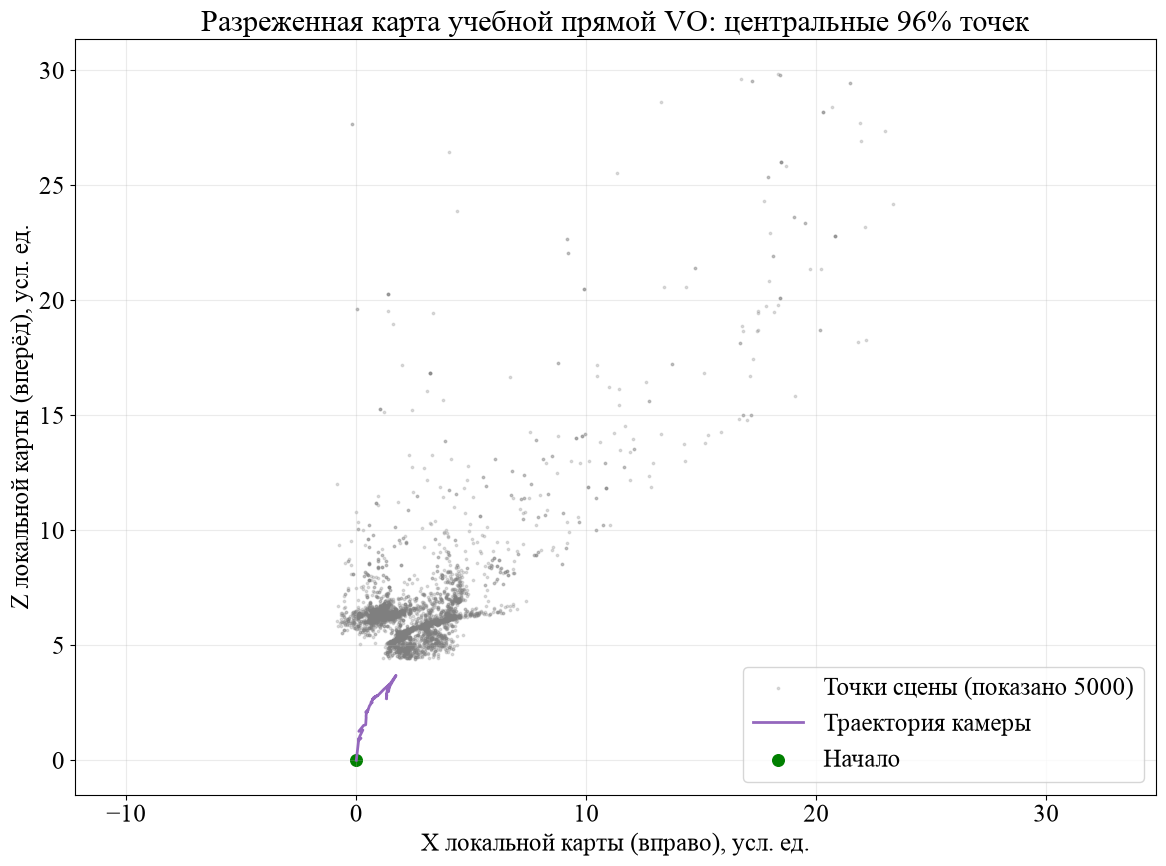

In [23]:
map_points_world = np.vstack(map_cloud)
finite_map = map_points_world[np.isfinite(map_points_world).all(axis=1)]
# Отбрасываем из РИСУНКА по 2% крайних значений с каждой стороны X и Z.
# Это не фильтрация карты в алгоритме: полный map_points_world остаётся без изменений.
lower, upper = np.percentile(finite_map[:, [0, 2]], [2, 98], axis=0)
central = ((finite_map[:, 0] >= lower[0]) & (finite_map[:, 0] <= upper[0]) &
           (finite_map[:, 2] >= lower[1]) & (finite_map[:, 2] <= upper[1]))
visible_map = finite_map[central]
# Равномерное прореживание ограничивает только число рисуемых точек.
if len(visible_map) > 5000:
    draw_indices = np.linspace(0, len(visible_map) - 1, 5000).astype(int)
    draw_map = visible_map[draw_indices]
else:
    draw_map = visible_map

figure, axis = plt.subplots(figsize=(12, 9))
axis.scatter(draw_map[:, 0], draw_map[:, 2], s=3, color='tab:gray', alpha=0.25,
             label=f'Точки сцены (показано {len(draw_map)})')
axis.plot(centers[:, 0], centers[:, 2], color='tab:purple', linewidth=2.0, label='Траектория камеры')
axis.scatter(*centers[0, [0, 2]], color='green', s=70, label='Начало')
axis.set(xlabel='X локальной карты (вправо), усл. ед.',
         ylabel='Z локальной карты (вперёд), усл. ед.',
         title='Разреженная карта учебной прямой VO: центральные 96% точек')
axis.axis('equal')
axis.grid(alpha=0.25)
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS_DIR / 'dso_map.png', dpi=200, bbox_inches='tight')
print(f'Карта: {len(finite_map)} конечных 3D-точек; центральная область: {len(visible_map)}; '
      f'на рисунке {len(draw_map)}')
print('ВЫВОД: карта показывает геометрический результат прямого метода, но не доказывает метрическую точность.')

## 9. Проверка и выводы

Маленькая фотометрическая невязка означает согласие яркостей, но не обязательно верную геометрию: возможны компенсация экспозиции, повторяющаяся текстура и неправильная глубина. Поэтому учитываем покрытие, число точек, размер скачка позы и последующие ГНСС-метрики. Сохранённые TUM/CSV/JSON и рисунки позволяют повторно сравнить метод с ORB после применения одинаковой маски.

In [24]:
tracked_rows = [row for row in diagnostics if row['status'] == 'tracked']
runtimes = np.array([row['runtime_s'] for row in tracked_rows])
residuals = np.array([row['median_residual'] for row in tracked_rows])
points = np.array([row['valid_points'] for row in tracked_rows])
summary = {
    'algorithm': 'educational_direct_sparse_vo_not_original_dso',
    'frames': len(image_paths), 'valid_poses': len(successful_poses),
    'completeness': len(successful_poses) / len(image_paths), 'lost_frames': lost_frames,
    'keyframes': sum(row['keyframe'] for row in diagnostics),
    'map_points_with_duplicates': int(len(map_points_world)),
    'mask_excluded_percent': float(excluded_percent),
    'median_valid_points': float(np.median(points)) if len(points) else None,
    'median_photometric_residual_gray': float(np.nanmedian(residuals)) if len(residuals) else None,
    'runtime_mean_s': float(runtimes.mean()) if len(runtimes) else None,
    'runtime_p95_s': float(np.percentile(runtimes, 95)) if len(runtimes) else None,
    'mono_scale_constant': MONO_SCALE_CONSTANT,
    'calibration_warning': 'Temporary fx/fy estimate; not a checkerboard calibration',
    'limitations': 'No photometric bundle adjustment, marginalization, or original DSO initializer',
}
(RESULTS_DIR / 'dso_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(summary, ensure_ascii=False, indent=2))

{
  "algorithm": "educational_direct_sparse_vo_not_original_dso",
  "frames": 599,
  "valid_poses": 590,
  "completeness": 0.9849749582637729,
  "lost_frames": [],
  "keyframes": 119,
  "map_points_with_duplicates": 422700,
  "mask_excluded_percent": 27.447591145833332,
  "median_valid_points": 3616.0,
  "median_photometric_residual_gray": 2.063570022583008,
  "runtime_mean_s": 0.13691476224831065,
  "runtime_p95_s": 0.22771815934902404,
  "mono_scale_constant": 1.0,
  "calibration_warning": "Temporary fx/fy estimate; not a checkerboard calibration",
  "limitations": "No photometric bundle adjustment, marginalization, or original DSO initializer"
}
